# hLDA — Hierarchical Latent Dirichlet Allocation
**Modeling**

Implements a hierarchical LDA model following the CRISP-DM modeling phase.  
Library: `tomotopy` (Collapsed Gibbs Sampling, `HLDAModel`).  
Input: page-level token lists produced by `src/utils.py` — same corpus as the primary flat-LDA baseline (`lda-page-cgs`).  
Granularity: one document = one slide page (≥ 10 tokens after preprocessing).  
Tree depth: 3 levels (root → mid-level → leaf).

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation
3. Hyperparameter Grid Search (α × η × γ)
4. Best Model Training & Topic Inspection
5. Topic Labeling
6. Curriculum Alignment
7. Tree Visualisation (static + interactive)
8. Final Evaluation
   - 8.1 Intrinsic Metrics (overall C_v)
   - 8.2 Per-level Coherence (C_v per tree level)
   - 8.3 Topic Exclusivity (mean P(topic|word) over top-10 words)
   - 8.4 Evaluation Summary
9. Data-Nature Visualisations (topic × deck, per-topic metrics)

## 1. Setup & Data Loading

In [2]:
import os
import sys
import json
import warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches

_nb_dir = os.path.dirname(os.path.abspath('hlda-1.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']
LEVEL_COLOURS = ['#1B3F6B', '#2C5F8A', '#4C9BE8']  # root, mid, leaf

print('Libraries loaded.')

Libraries loaded.


In [3]:
from utils import load_corpus, tokenize_corpus, build_slide_page_docs

corpus = tokenize_corpus(load_corpus())

print(f'Corpus loaded: {len(corpus)} lines')

Corpus loaded: 1868 lines


## 2. Corpus Preparation

Identical to `lda-page-cgs`: page-level aggregation, `MIN_TOKENS = 10`.

In [4]:
import tomotopy as tp
from tomotopy.coherence import Coherence

RANDOM_SEED = 42
MIN_TOKENS  = 10
DEPTH       = 3   # root / mid-level / leaf

docs = build_slide_page_docs(corpus)
docs = docs[docs['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)

texts = docs['tokens'].tolist()

print(f'Documents (pages) : {len(docs)}')
print(f'Token count — min : {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
print(f'tomotopy version  : {tp.__version__}')

Dropping 6 empty pages after tokenisation.


Documents (pages) : 121
Token count — min : 10, median: 21, max: 69
tomotopy version  : 0.14.0


In [5]:
from sklearn.model_selection import train_test_split

# 90/10 holdout split — model trained only on train set; test set used for perplexity evaluation
train_df, test_df = train_test_split(docs, test_size=0.10, random_state=RANDOM_SEED)
train_df    = train_df.reset_index(drop=True)
test_df     = test_df.reset_index(drop=True)
train_texts = train_df['tokens'].tolist()
test_texts  = test_df['tokens'].tolist()

print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')

Train: 108 docs | Test: 13 docs


## 3. Hyperparameter Grid Search

hLDA has three key hyperparameters:

| Parameter | Role |
|-----------|------|
| **α** | Dirichlet prior on document–topic assignment per level; higher = documents spread across more topics |
| **η** | Dirichlet prior on topic–word distributions; lower = sharper, more peaked topics |
| **γ** | Concentration parameter for the nested CRP; higher = more topics generated |

Grid: α ∈ {0.1, 0.5, 1.0}, η ∈ {0.01, 0.05, 0.1}, γ ∈ {0.1, 0.25, 0.5, 1.0} — 36 combinations.  
Each configuration is evaluated on C_v coherence and in-sample perplexity; the best configuration is selected by C_v.  
Iterations during search: 500 (reduced for speed); final model trained at 1000.

In [6]:
ALPHA_GRID = [0.1, 0.5, 1.0]
ETA_GRID   = [0.01, 0.05, 0.1]
GAMMA_GRID = [0.1, 0.25, 0.5, 1.0]

GRID_ITERATIONS  = 500
FINAL_ITERATIONS = 1000

grid_results = []

for alpha in ALPHA_GRID:
    for eta in ETA_GRID:
        for gamma in GAMMA_GRID:
            m = tp.HLDAModel(
                depth  = DEPTH,
                alpha  = alpha,
                eta    = eta,
                gamma  = gamma,
                min_df = 2,
                seed   = RANDOM_SEED,
            )
            for token_list in train_texts:
                m.add_doc(token_list)
            m.train(0)
            m.train(GRID_ITERATIONS, workers=1)

            cv    = Coherence(m, coherence='c_v').get_score()
            perp  = m.perplexity
            live  = m.live_k

            grid_results.append({
                'alpha': alpha, 'eta': eta, 'gamma': gamma,
                'coherence_cv': round(cv, 4),
                'perplexity':   round(perp, 2),
                'live_topics':  int(live),
            })
            print(f'α={alpha}  η={eta}  γ={gamma:4}  →  C_v={cv:.4f}  perp={perp:.1f}  live_k={live}')

grid_df = pd.DataFrame(grid_results)
best_row = grid_df.loc[grid_df['coherence_cv'].idxmax()]
print(f'\nBest → α={best_row.alpha}  η={best_row.eta}  γ={best_row.gamma}  C_v={best_row.coherence_cv}')

α=0.1  η=0.01  γ= 0.1  →  C_v=0.5669  perp=559.5  live_k=3
α=0.1  η=0.01  γ=0.25  →  C_v=0.7282  perp=517.1  live_k=5
α=0.1  η=0.01  γ= 0.5  →  C_v=0.7337  perp=521.4  live_k=5
α=0.1  η=0.01  γ= 1.0  →  C_v=0.7725  perp=466.5  live_k=10
α=0.1  η=0.05  γ= 0.1  →  C_v=0.5783  perp=448.2  live_k=3
α=0.1  η=0.05  γ=0.25  →  C_v=0.7415  perp=409.0  live_k=5
α=0.1  η=0.05  γ= 0.5  →  C_v=0.7400  perp=408.0  live_k=6
α=0.1  η=0.05  γ= 1.0  →  C_v=0.7413  perp=384.6  live_k=10
α=0.1  η=0.1  γ= 0.1  →  C_v=0.5135  perp=417.8  live_k=3
α=0.1  η=0.1  γ=0.25  →  C_v=0.7435  perp=378.3  live_k=5
α=0.1  η=0.1  γ= 0.5  →  C_v=0.7348  perp=347.7  live_k=6
α=0.1  η=0.1  γ= 1.0  →  C_v=0.7409  perp=307.8  live_k=10
α=0.5  η=0.01  γ= 0.1  →  C_v=0.4955  perp=553.5  live_k=3
α=0.5  η=0.01  γ=0.25  →  C_v=0.7649  perp=545.9  live_k=5
α=0.5  η=0.01  γ= 0.5  →  C_v=0.7590  perp=525.7  live_k=5
α=0.5  η=0.01  γ= 1.0  →  C_v=0.7299  perp=480.5  live_k=10
α=0.5  η=0.05  γ= 0.1  →  C_v=0.5453  perp=447.5  live_k

In [7]:
# Grid search results table — top 10 by C_v
print('Top 10 configurations by C_v coherence:')
display(
    grid_df.sort_values('coherence_cv', ascending=False)
           .head(10)
           .reset_index(drop=True)
           .style.format({
               'coherence_cv': '{:.4f}',
               'perplexity':   '{:.2f}',
           })
           .bar(subset=['coherence_cv'], color='#2C5F8A', vmin=0, vmax=1)
)

Top 10 configurations by C_v coherence:


,alpha,eta,gamma,coherence_cv,perplexity,live_topics
0,0.100000,0.010000,1.000000,0.7725,466.53,10
1,1.000000,0.050000,1.000000,0.7678,376.81,10
2,0.500000,0.010000,0.250000,0.7649,545.86,5
3,1.000000,0.010000,1.000000,0.7649,470.07,10
4,0.500000,0.050000,1.000000,0.7602,357.75,10
5,0.500000,0.010000,0.500000,0.7590,525.72,5
6,1.000000,0.010000,0.500000,0.7564,542.52,5
7,1.000000,0.100000,1.000000,0.7514,326.89,10
8,0.500000,0.100000,1.000000,0.7511,334.19,10
9,1.000000,0.100000,0.500000,0.7473,356.57,6


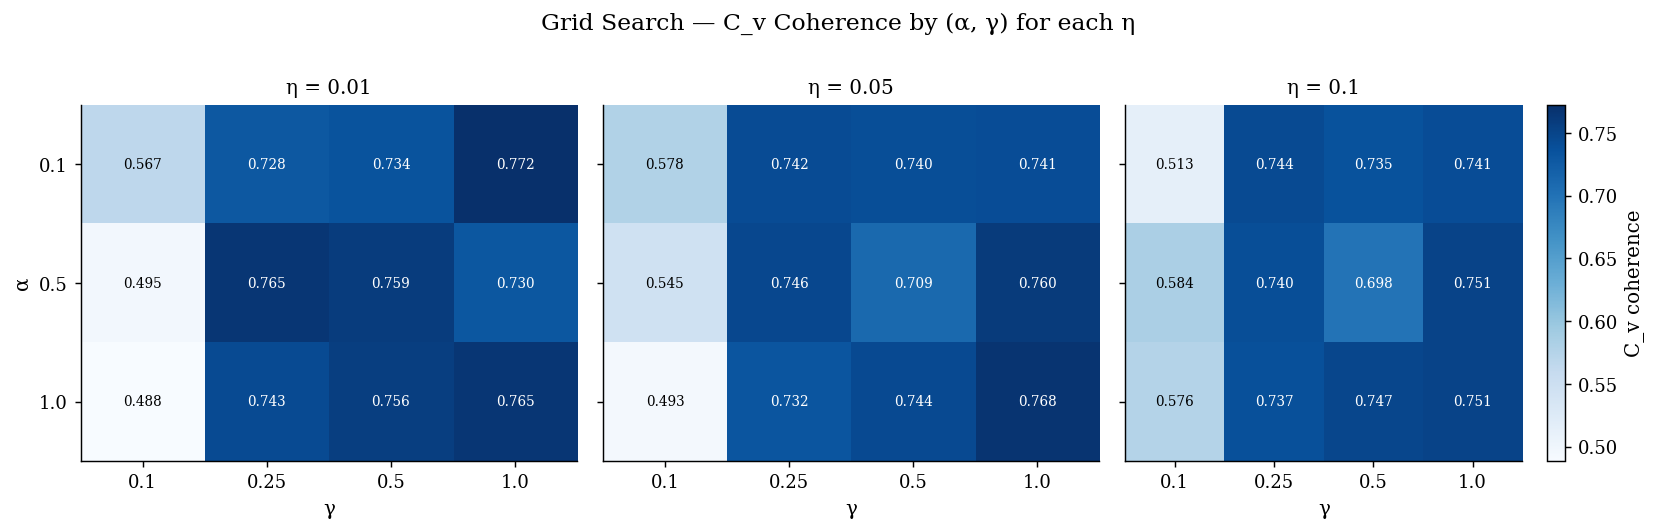

In [8]:
# Heatmap: C_v by γ and α for each η value
fig, axes = plt.subplots(1, len(ETA_GRID), figsize=(13, 4), sharey=True)

for ax, eta_val in zip(axes, ETA_GRID):
    sub = grid_df[grid_df['eta'] == eta_val]
    pivot = sub.pivot(index='alpha', columns='gamma', values='coherence_cv')
    im = ax.imshow(pivot.values, cmap='Blues', vmin=grid_df.coherence_cv.min(),
                   vmax=grid_df.coherence_cv.max(), aspect='auto')
    ax.set_xticks(range(len(GAMMA_GRID)))
    ax.set_xticklabels(GAMMA_GRID)
    ax.set_yticks(range(len(ALPHA_GRID)))
    ax.set_yticklabels(ALPHA_GRID)
    ax.set_title(f'η = {eta_val}', fontsize=11)
    ax.set_xlabel('γ')
    if ax is axes[0]:
        ax.set_ylabel('α')
    for i in range(len(ALPHA_GRID)):
        for j in range(len(GAMMA_GRID)):
            ax.text(j, i, f'{pivot.values[i, j]:.3f}', ha='center', va='center',
                    fontsize=7.5, color='white' if pivot.values[i, j] > 0.6 else 'black')

fig.colorbar(im, ax=axes[-1], label='C_v coherence')
fig.suptitle('Grid Search — C_v Coherence by (α, γ) for each η', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 4. Best Model Training & Topic Inspection

In [9]:
# Extract best hyperparameters from grid search and retrain at full iterations.
BEST_ALPHA = float(best_row['alpha'])
BEST_ETA   = float(best_row['eta'])
BEST_GAMMA = float(best_row['gamma'])

hlda = tp.HLDAModel(
    depth  = DEPTH,
    alpha  = BEST_ALPHA,
    eta    = BEST_ETA,
    gamma  = BEST_GAMMA,
    min_df = 2,
    seed   = RANDOM_SEED,
)

for token_list in train_texts:
    hlda.add_doc(token_list)

hlda.train(0)
hlda.train(FINAL_ITERATIONS, workers=1)

print(f'hLDA trained: depth={DEPTH}, α={BEST_ALPHA}, η={BEST_ETA}, γ={BEST_GAMMA}')
print(f'Iterations   : {FINAL_ITERATIONS}, seed={RANDOM_SEED}')
print(f'Vocabulary   : {hlda.num_vocabs} terms')
print(f'Live topics  : {hlda.live_k}')
print(f'Total topics : {hlda.k}')
print(f'Train docs   : {len(train_texts)}')

hLDA trained: depth=3, α=0.1, η=0.01, γ=1.0
Iterations   : 1000, seed=42
Vocabulary   : 373 terms
Live topics  : 10
Total topics : 24
Train docs   : 108


In [10]:
# Reconstruct tree topology
def get_topic_level(model):
    """Return {topic_id: level} for every live topic (level 0 = root)."""
    return {tid: model.level(tid) for tid in range(model.k) if model.is_live_topic(tid)}

def get_topic_children(model):
    """Return {parent_id: [child_id, ...]} for every live topic."""
    children = {}
    for tid in range(model.k):
        if model.is_live_topic(tid):
            children[tid] = [c for c in model.children_topics(tid) if model.is_live_topic(c)]
    return children

level_map    = get_topic_level(hlda)
children_map = get_topic_children(hlda)

by_level = defaultdict(list)
for tid, lvl in sorted(level_map.items()):
    by_level[lvl].append(tid)

level_names = {0: 'Root', 1: 'Mid-level', 2: 'Leaf'}
for lvl in sorted(by_level):
    tids = by_level[lvl]
    print(f'Level {lvl} ({level_names.get(lvl, lvl)}): {len(tids)} topic(s) — ids: {tids}')

Level 0 (Root): 1 topic(s) — ids: [0]
Level 1 (Mid-level): 2 topic(s) — ids: [8, 9]
Level 2 (Leaf): 7 topic(s) — ids: [16, 17, 18, 19, 20, 21, 22]


In [11]:
# Top terms per live topic, grouped by level.
TOP_N = 10

for lvl in sorted(by_level):
    print(f'\n=== {level_names.get(lvl, f"Level {lvl}")} topics ===')
    for tid in by_level[lvl]:
        terms    = hlda.get_topic_words(tid, top_n=TOP_N)
        term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
        children = sorted(children_map.get(tid, []))
        child_str = f'  → children: {children}' if children else ''
        print(f'  T{tid:03d}: {term_str}{child_str}')


=== Root topics ===
  T000: 0.072*"informação" + 0.044*"numérico" + 0.034*"aluno" + 0.034*"problema" + 0.031*"tratamento" + 0.026*"imagem" + 0.023*"conteúdo" + 0.021*"qualidade" + 0.018*"volume" + 0.016*"pessoa"  → children: [np.uint32(8), np.uint32(9)]

=== Mid-level topics ===
  T008: 0.098*"modelo" + 0.047*"resultado" + 0.042*"conjunto" + 0.042*"objetivo" + 0.031*"classificação" + 0.029*"previsão" + 0.024*"treino" + 0.024*"base" + 0.022*"avaliação" + 0.020*"algoritmo"  → children: [np.uint32(16), np.uint32(17), np.uint32(18), np.uint32(19), np.uint32(21), np.uint32(22)]
  T009: 0.151*"visualização" + 0.076*"barra" + 0.051*"people" + 0.051*"looking" + 0.051*"mensagem" + 0.051*"coluna" + 0.051*"entanto" + 0.051*"artificial" + 0.051*"gráfico" + 0.025*"contexto"  → children: [np.uint32(20)]

=== Leaf topics ===
  T016: 0.084*"direito" + 0.072*"empresa" + 0.060*"correlação" + 0.060*"europeu" + 0.048*"ataque" + 0.048*"análise" + 0.036*"fonte" + 0.036*"segurança" + 0.036*"enorme" + 0.024*

## 5. Topic Labeling

Each live topic is labelled by an institutional **LLM proxy** (an OpenAI-compatible LiteLLM/Hyperspace endpoint) in two modes:

- **Few-shot** — the prompt is anchored to the known IDS curriculum (`IDS_COURSE_TOPICS`), nudging labels toward the nine course units.
- **Zero-shot** — the label is derived from the topic keywords alone, with no curriculum anchor.

Comparing the two isolates how much the labelling depends on prior knowledge of the syllabus. If zero-shot labels recover the same themes without anchoring, that is evidence the topic model captured genuine structure rather than the anchor doing the work.

> Requires `LITELLM_BASE_URL`, `LITELLM_API_KEY`, and `AICORE_MODEL` in `.env`. On any API error each topic falls back to a keyword-join label, so the notebook always completes. Because the proxy is a stochastic LLM, the labels and the agreement rate are a single-draw, non-deterministic result.

In [12]:
from utils import generate_topic_labels_llm

live_tids = sorted(level_map.keys())

# Label only live topics (hLDA leaves many dead ids) — halves the API calls.
LABELS_FEWSHOT  = generate_topic_labels_llm(hlda, hlda.k, use_course_topics=True,  topic_ids=live_tids)
LABELS_ZEROSHOT = generate_topic_labels_llm(hlda, hlda.k, use_course_topics=False, topic_ids=live_tids)

# Downstream plots use ALL_LABELS; few-shot labels are the more readable default.
ALL_LABELS = LABELS_FEWSHOT

print('Topic labels — few-shot (anchored) vs zero-shot (keywords only):')
for lvl in sorted(by_level):
    print(f'\n  {level_names.get(lvl, lvl)}:')
    for tid in by_level[lvl]:
        print(f'    T{tid:03d}: few-shot = {LABELS_FEWSHOT.get(tid, "—"):30s} | '
              f'zero-shot = {LABELS_ZEROSHOT.get(tid, "—")}')

Topic labels — few-shot (anchored) vs zero-shot (keywords only):

  Root:
    T000: few-shot = Fundamentos de dados           | zero-shot = Data Quality and Processing

  Mid-level:
    T008: few-shot = Modelagem supervisionada       | zero-shot = Machine learning workflow
    T009: few-shot = Visualização de dados          | zero-shot = data visualization methods

  Leaf:
    T016: few-shot = Ética e Segurança Dados        | zero-shot = Corporate Security Analysis
    T017: few-shot = Modelos de Inteligência Artificial | zero-shot = Artificial Intelligence Metrics
    T018: few-shot = Modelação Supervisada          | zero-shot = Regression and classification features
    T019: few-shot = Introdução à Ciência de Dados  | zero-shot = Data Science Process
    T020: few-shot = Amostragem e Probabilidade     | zero-shot = Sampling and Population Concepts
    T021: few-shot = Detecção de outliers           | zero-shot = Data quality issues
    T022: few-shot = Modelação Não Supervisionada  

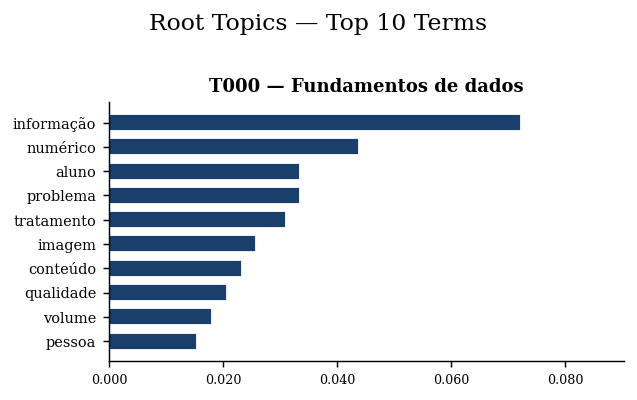

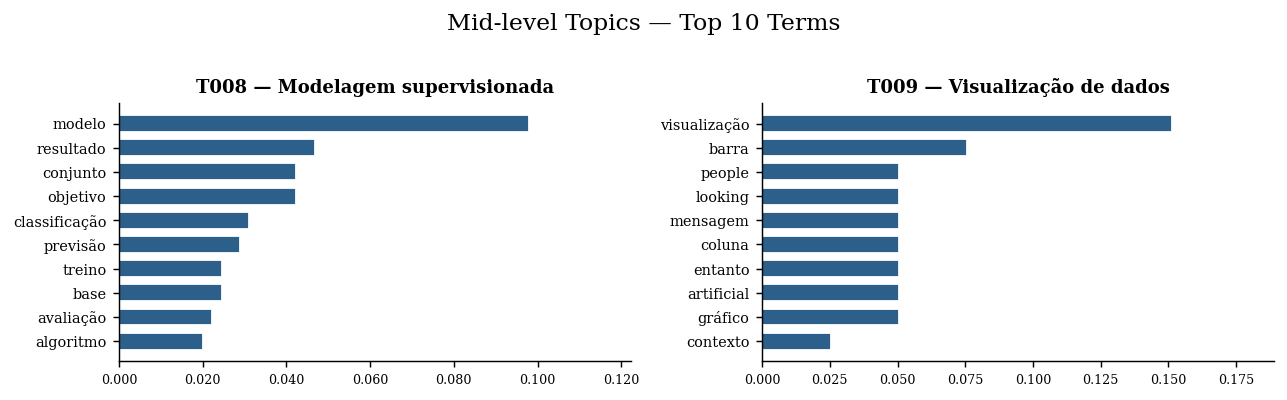

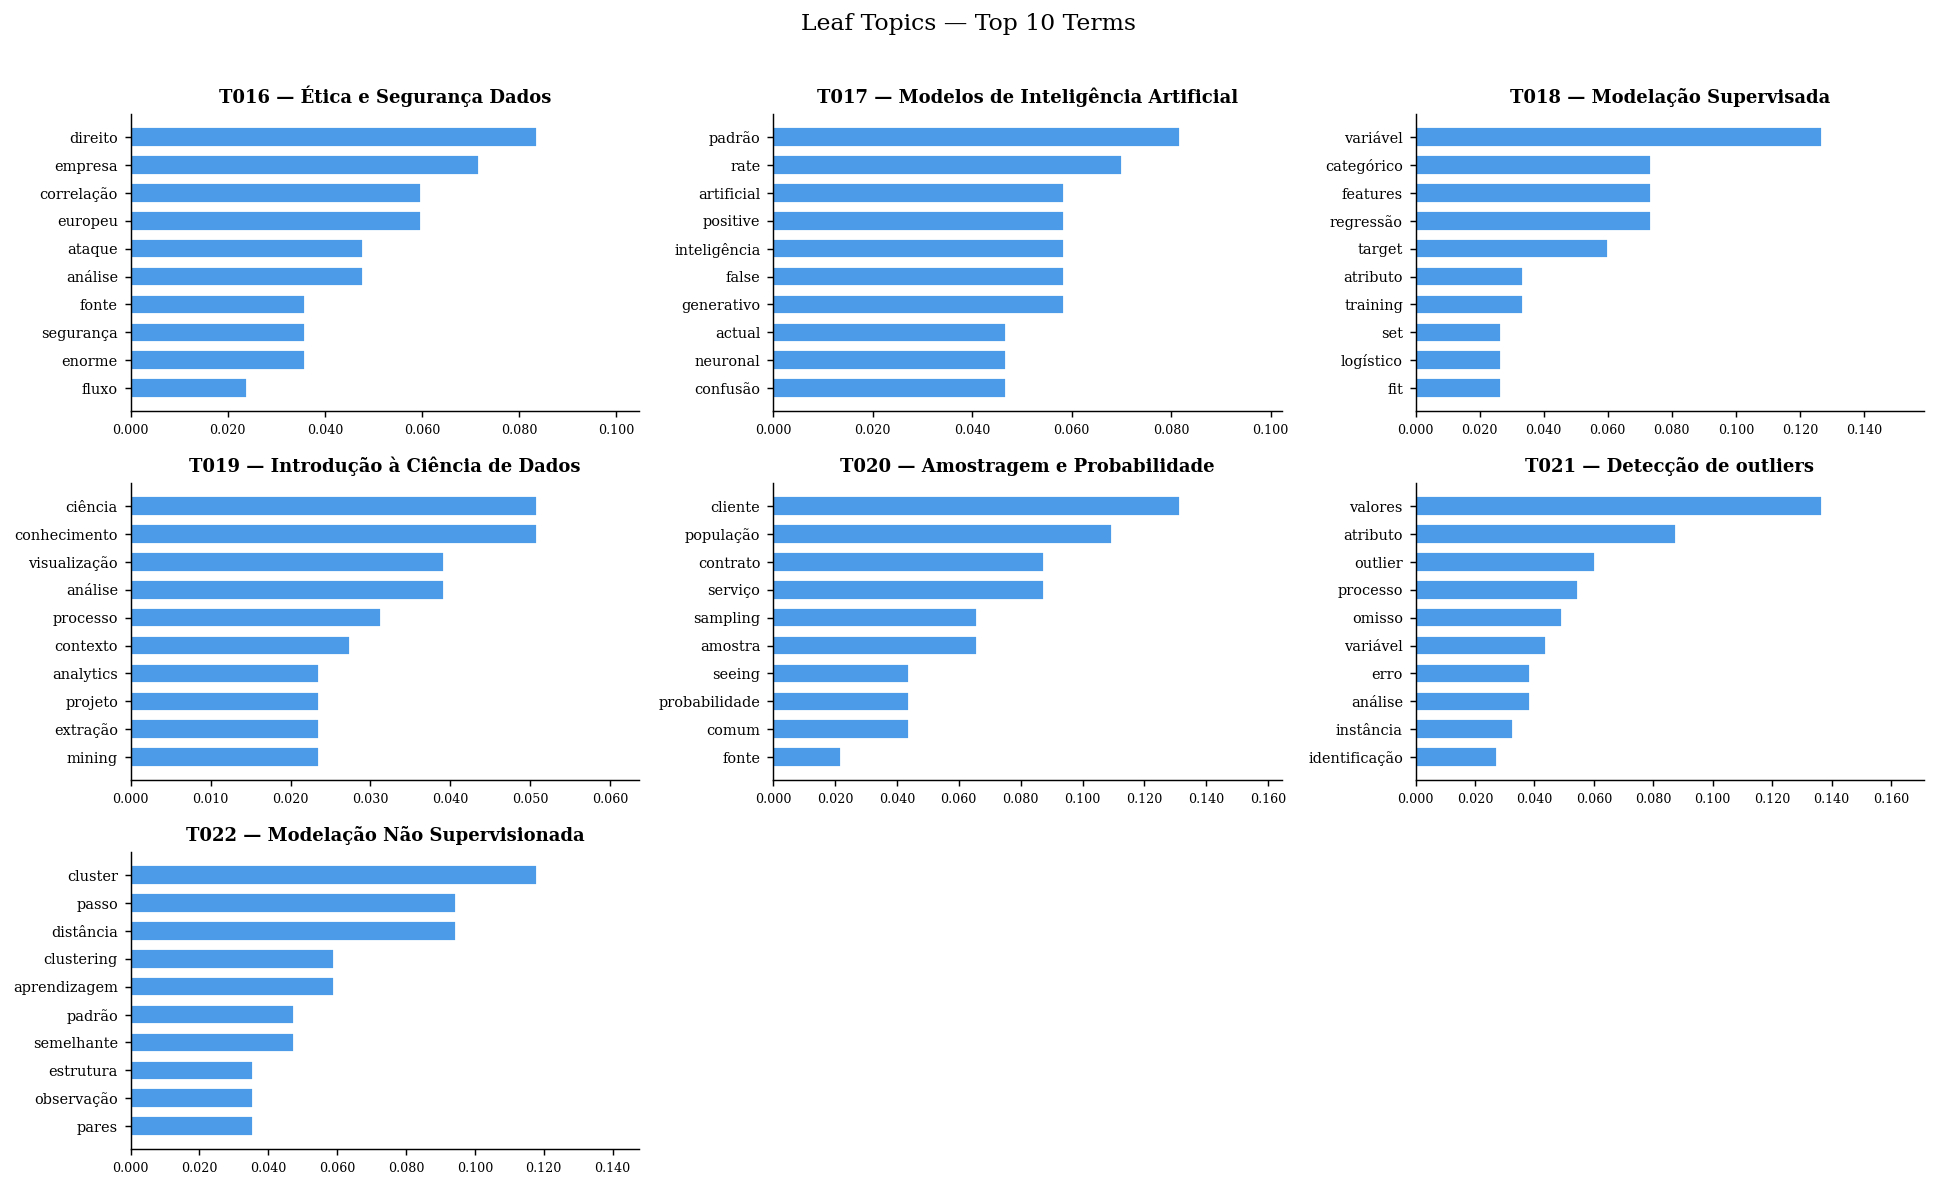

In [13]:
# Topic profiles: bar charts for each live topic, grouped by level.
for lvl in sorted(by_level):
    tids   = by_level[lvl]
    n_cols = min(len(tids), 3)
    n_rows = (len(tids) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 3))
    axes = np.array(axes).flatten()

    for i, tid in enumerate(tids):
        terms   = hlda.get_topic_words(tid, top_n=TOP_N)
        words   = [w for w, _ in terms][::-1]
        weights = [p for _, p in terms][::-1]
        ax = axes[i]
        ax.barh(words, weights, color=LEVEL_COLOURS[lvl], edgecolor='white', height=0.7)
        ax.set_title(f'T{tid:03d} — {ALL_LABELS.get(tid, "")}', fontsize=10, fontweight='bold')
        ax.set_xlim(0, max(weights) * 1.25)
        ax.tick_params(axis='y', labelsize=8)
        ax.tick_params(axis='x', labelsize=7)
        ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

    for j in range(len(tids), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(f'{level_names.get(lvl, lvl)} Topics — Top {TOP_N} Terms', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

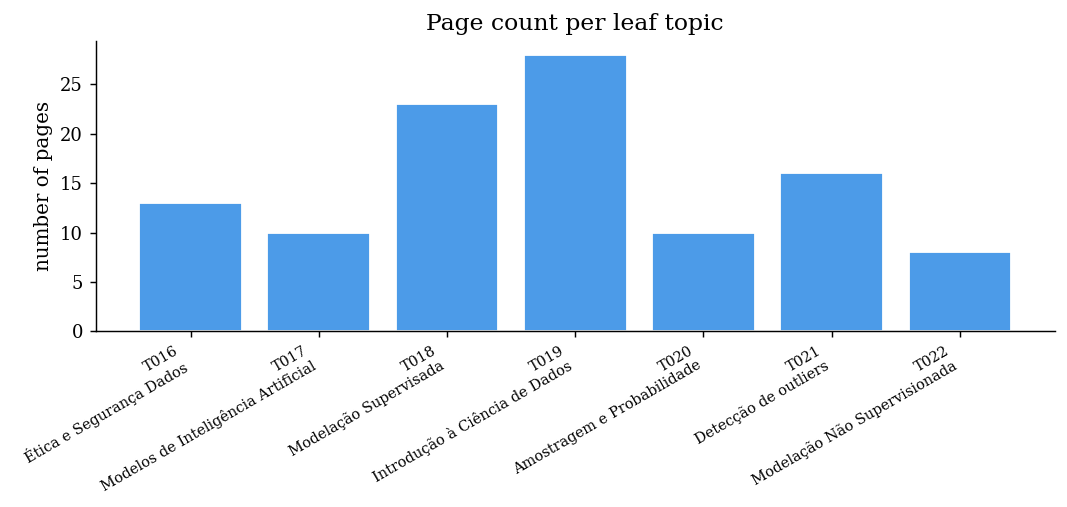

Pages per leaf topic:
  T016: 13 page(s)
  T017: 10 page(s)
  T018: 23 page(s)
  T019: 28 page(s)
  T020: 10 page(s)
  T021: 16 page(s)
  T022: 8 page(s)


In [14]:
# Document-path distribution: how many pages are assigned to each leaf topic.
leaf_tids = by_level.get(DEPTH - 1, [])

leaf_counts = {tid: hlda.num_docs_of_topic(tid) for tid in leaf_tids}

leaf_ids    = sorted(leaf_tids)
counts      = [leaf_counts.get(tid, 0) for tid in leaf_ids]
leaf_labels = [f'T{tid:03d}\n{ALL_LABELS.get(tid, "")}' for tid in leaf_ids]

fig, ax = plt.subplots(figsize=(max(6, len(leaf_ids) * 1.2), 4))
ax.bar(range(len(leaf_ids)), counts, color=LEVEL_COLOURS[2], edgecolor='white')
ax.set_xticks(range(len(leaf_ids)))
ax.set_xticklabels(leaf_labels, fontsize=8, rotation=30, ha='right')
ax.set_ylabel('number of pages')
ax.set_title('Page count per leaf topic')
plt.tight_layout()
plt.show()

print('Pages per leaf topic:')
for tid in sorted(leaf_counts):
    print(f'  T{tid:03d}: {leaf_counts[tid]} page(s)')

In [15]:
# Tree structure summary table
rows = []
for lvl in sorted(by_level):
    for tid in by_level[lvl]:
        terms = hlda.get_topic_words(tid, top_n=5)
        rows.append({
            'Topic ID':  f'T{tid:03d}',
            'Level':     f'{lvl} ({level_names.get(lvl, lvl)})',
            'Label':     ALL_LABELS.get(tid, '—'),
            'Top 5 Terms': ', '.join(w for w, _ in terms),
            'Children':  str(sorted(children_map.get(tid, []))),
            'Pages':     int(leaf_counts.get(tid, 0)) if lvl == DEPTH - 1 else '—',
        })

tree_df = pd.DataFrame(rows).set_index('Topic ID')
tree_df.style \
    .set_caption('hLDA Tree Structure — All Live Topics') \
    .set_properties(**{'text-align': 'left'})

,Level,Label,Top 5 Terms,Children,Pages
Topic ID,,,,,
T000,0 (Root),Fundamentos de dados,"informação, numérico, aluno, problema, tratamento","[np.uint32(8), np.uint32(9)]",—
T008,1 (Mid-level),Modelagem supervisionada,"modelo, resultado, conjunto, objetivo, classificação","[np.uint32(16), np.uint32(17), np.uint32(18), np.uint32(19), np.uint32(21), np.uint32(22)]",—
T009,1 (Mid-level),Visualização de dados,"visualização, barra, people, looking, mensagem",[np.uint32(20)],—
T016,2 (Leaf),Ética e Segurança Dados,"direito, empresa, correlação, europeu, ataque",[],13
T017,2 (Leaf),Modelos de Inteligência Artificial,"padrão, rate, artificial, positive, inteligência",[],10
T018,2 (Leaf),Modelação Supervisada,"variável, categórico, features, regressão, target",[],23
T019,2 (Leaf),Introdução à Ciência de Dados,"ciência, conhecimento, visualização, análise, processo",[],28
T020,2 (Leaf),Amostragem e Probabilidade,"cliente, população, contrato, serviço, sampling",[],10
T021,2 (Leaf),Detecção de outliers,"valores, atributo, outlier, processo, omisso",[],16


## 6. Curriculum Alignment

Each live topic is classified — again by the institutional LLM proxy — to the single IDS unit (ICD1–ICD9) it best matches, using the topic keywords plus its candidate label. Running the alignment on both label sets yields an **agreement rate**: the fraction of topics whose zero-shot and few-shot alignments land on the same unit.

High agreement means the discovered topics map to the same curriculum units with or without the anchor — evidence that the topic structure, not the prompt, carries the signal. The proportion of topics unambiguously assigned to a teaching unit is reported as an indication of curriculum coverage.

In [16]:
from utils import align_topics_to_units, IDS_COURSE_TOPICS

# Align live topics only — same optimisation as in the labelling cell.
align_fewshot  = align_topics_to_units(hlda, hlda.k, labels=LABELS_FEWSHOT,  topic_ids=live_tids)
align_zeroshot = align_topics_to_units(hlda, hlda.k, labels=LABELS_ZEROSHOT, topic_ids=live_tids)

rows = []
for lvl in sorted(by_level):
    for tid in by_level[lvl]:
        terms = hlda.get_topic_words(tid, top_n=5)
        u_few  = align_fewshot[tid]['unit']
        u_zero = align_zeroshot[tid]['unit']
        rows.append({
            'Topic ID':          f'T{tid:03d}',
            'Level':             level_names.get(lvl, lvl),
            'Top 5 Terms':       ', '.join(w for w, _ in terms),
            'Label (few-shot)':  LABELS_FEWSHOT.get(tid, '—'),
            'Label (zero-shot)': LABELS_ZEROSHOT.get(tid, '—'),
            'Unit (few-shot)':   u_few or '—',
            'Unit (zero-shot)':  u_zero or '—',
            'Match':             '✓' if (u_few is not None and u_few == u_zero) else '',
        })

align_df = pd.DataFrame(rows).set_index('Topic ID')

# Agreement rate over live topics.
n_live    = len(live_tids)
n_matched = sum(1 for tid in live_tids
                if align_fewshot[tid]['unit'] is not None
                and align_fewshot[tid]['unit'] == align_zeroshot[tid]['unit'])
agreement = n_matched / n_live if n_live else 0.0

print(f'Zero-shot vs few-shot unit agreement: {n_matched}/{n_live} = {agreement:.1%}')
print(f'Units covered (few-shot) : {sorted({v["unit"] for v in align_fewshot.values() if v["unit"]})}')
print(f'Units covered (zero-shot): {sorted({v["unit"] for v in align_zeroshot.values() if v["unit"]})}')

display(
    align_df.style
        .set_caption('Topic labels and IDS-unit alignment — zero-shot vs few-shot')
        .set_properties(**{'text-align': 'left'})
)

Zero-shot vs few-shot unit agreement: 10/10 = 100.0%
Units covered (few-shot) : ['ICD1', 'ICD2', 'ICD3', 'ICD4', 'ICD6', 'ICD7', 'ICD8']
Units covered (zero-shot): ['ICD1', 'ICD2', 'ICD3', 'ICD4', 'ICD6', 'ICD7', 'ICD8']


,Level,Top 5 Terms,Label (few-shot),Label (zero-shot),Unit (few-shot),Unit (zero-shot),Match
Topic ID,,,,,,,
T000,Root,"informação, numérico, aluno, problema, tratamento",Fundamentos de dados,Data Quality and Processing,ICD6,ICD6,✓
T008,Mid-level,"modelo, resultado, conjunto, objetivo, classificação",Modelagem supervisionada,Machine learning workflow,ICD7,ICD7,✓
T009,Mid-level,"visualização, barra, people, looking, mensagem",Visualização de dados,data visualization methods,ICD4,ICD4,✓
T016,Leaf,"direito, empresa, correlação, europeu, ataque",Ética e Segurança Dados,Corporate Security Analysis,ICD2,ICD2,✓
T017,Leaf,"padrão, rate, artificial, positive, inteligência",Modelos de Inteligência Artificial,Artificial Intelligence Metrics,ICD7,ICD7,✓
T018,Leaf,"variável, categórico, features, regressão, target",Modelação Supervisada,Regression and classification features,ICD7,ICD7,✓
T019,Leaf,"ciência, conhecimento, visualização, análise, processo",Introdução à Ciência de Dados,Data Science Process,ICD1,ICD1,✓
T020,Leaf,"cliente, população, contrato, serviço, sampling",Amostragem e Probabilidade,Sampling and Population Concepts,ICD3,ICD3,✓
T021,Leaf,"valores, atributo, outlier, processo, omisso",Detecção de outliers,Data quality issues,ICD6,ICD6,✓


## 7. Tree Visualisation

The core view of a hierarchical model: the root → mid → leaf topic tree, with each node showing its label and leading terms. Two renderings are produced from the same `children_map`:

- **Static** (matplotlib + networkx) — deterministic top-down layout, colour-coded by level, exported to `data/output/` as PNG/PDF for the thesis.
- **Interactive** (plotly icicle) — hover reveals the top terms and page counts, for exploration.

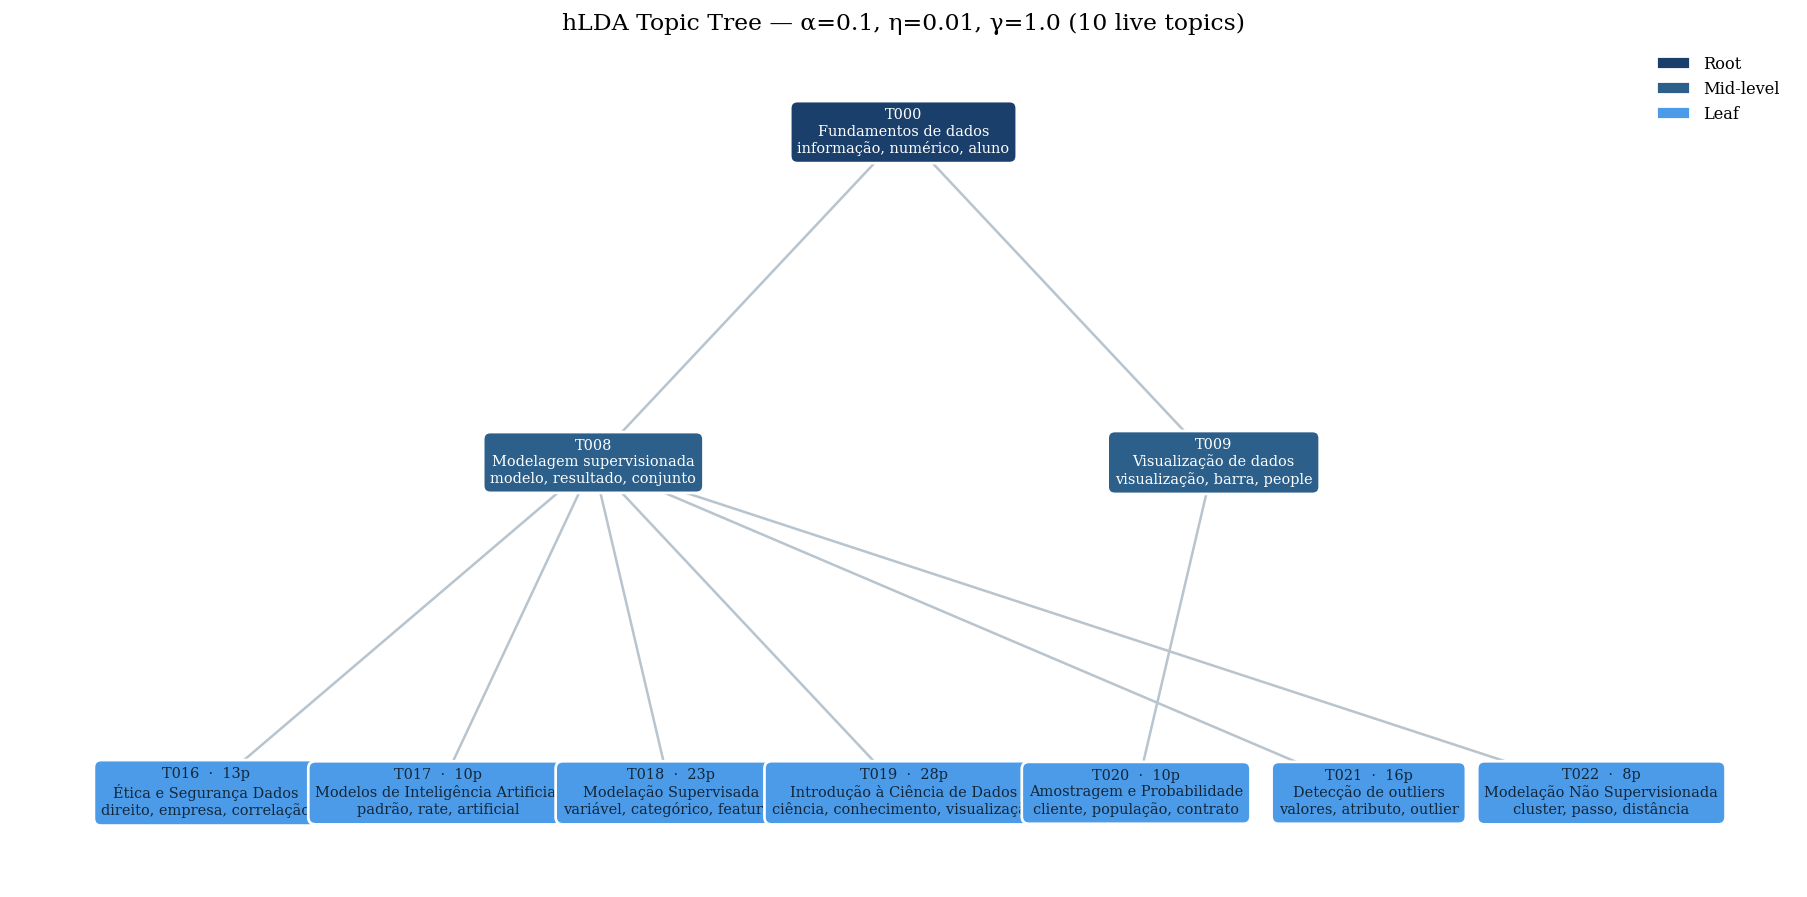

Static tree saved to:
  /Users/I749701/Developer/University/MIGThesis-126735/data/output/hlda_tree.png
  /Users/I749701/Developer/University/MIGThesis-126735/data/output/hlda_tree.pdf


In [17]:
# Static tree
import networkx as nx
from utils import OUTPUT_ROOT

TOP_TERMS_NODE = 3   # terms shown inside each node

def _node_text(tid):
    terms = hlda.get_topic_words(tid, top_n=TOP_TERMS_NODE)
    words = ', '.join(w for w, _ in terms)
    label = ALL_LABELS.get(tid, '')
    pages = leaf_counts.get(tid)
    head  = f'T{tid:03d}' + (f'  ·  {pages}p' if pages else '')
    return f'{head}\n{label}\n{words}'

# Build the directed tree from children_map (cast tomotopy uint ids to int).
G = nx.DiGraph()
for parent, kids in children_map.items():
    G.add_node(int(parent))
    for c in kids:
        G.add_edge(int(parent), int(c))

# Deterministic top-down layout: y by level (root on top), x spread evenly per level.
pos = {}
for lvl in sorted(by_level):
    tids = by_level[lvl]
    n = len(tids)
    for i, tid in enumerate(sorted(tids)):
        x = (i + 1) / (n + 1)            # evenly spaced in (0, 1)
        y = -lvl                          # 0=root at top, deeper levels lower
        pos[int(tid)] = (x, y)

fig, ax = plt.subplots(figsize=(max(11, len(by_level.get(2, [])) * 2.0), 7))

# Edges first (recessive), then nodes on top.
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#B8C4CE', width=1.4,
                       arrows=False, node_size=0)

for lvl in sorted(by_level):
    for tid in by_level[lvl]:
        x, y = pos[int(tid)]
        ax.text(
            x, y, _node_text(tid),
            ha='center', va='center', fontsize=8, zorder=3,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=LEVEL_COLOURS[lvl],
                      edgecolor='white', linewidth=1.5),
            color='white' if lvl == 0 else ('white' if lvl == 1 else '#12263A'),
        )

# Level legend (identity is never colour-alone: the y-axis order also encodes depth).
handles = [mpatches.Patch(facecolor=LEVEL_COLOURS[lvl], edgecolor='white',
                          label=level_names.get(lvl, f'Level {lvl}'))
           for lvl in sorted(by_level)]
ax.legend(handles=handles, loc='upper right', frameon=False, fontsize=9)

ax.set_title(f'hLDA Topic Tree — α={BEST_ALPHA}, η={BEST_ETA}, γ={BEST_GAMMA} '
             f'({hlda.live_k} live topics)', fontsize=13)
ax.margins(0.08)
ax.axis('off')
plt.tight_layout()

os.makedirs(OUTPUT_ROOT, exist_ok=True)
png_path = os.path.join(OUTPUT_ROOT, 'hlda_tree.png')
pdf_path = os.path.join(OUTPUT_ROOT, 'hlda_tree.pdf')
fig.savefig(png_path, dpi=200, bbox_inches='tight')
fig.savefig(pdf_path, bbox_inches='tight')
plt.show()
print(f'Static tree saved to:\n  {png_path}\n  {pdf_path}')

In [18]:
# Interactive tree — hover shows terms + page counts.
import plotly.graph_objects as go

ids, parents, labels, customdata, colours = [], [], [], [], []

for lvl in sorted(by_level):
    for tid in by_level[lvl]:
        node_id = f'T{tid:03d}'
        # Root has no parent; others point to their tomotopy parent topic.
        if lvl == 0:
            parent_id = ''
        else:
            p = int(hlda.parent_topic(tid))
            parent_id = f'T{p:03d}'

        terms = hlda.get_topic_words(tid, top_n=8)
        term_str = '<br>'.join(f'{w} ({p:.3f})' for w, p in terms)
        pages = leaf_counts.get(tid, 0)

        ids.append(node_id)
        parents.append(parent_id)
        labels.append(f'{node_id}<br>{ALL_LABELS.get(tid, "")}')
        customdata.append([level_names.get(lvl, lvl), pages, term_str])
        colours.append(LEVEL_COLOURS[lvl])

fig = go.Figure(go.Icicle(
    ids=ids,
    parents=parents,
    labels=labels,
    marker=dict(colors=colours),
    tiling=dict(orientation='v'),
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Level: %{customdata[0]}<br>'
        'Pages: %{customdata[1]}<br>'
        '<br>Top terms:<br>%{customdata[2]}<extra></extra>'
    ),
    customdata=customdata,
    root_color='white',
))
fig.update_layout(
    title=f'hLDA Topic Tree (interactive) — {hlda.live_k} live topics',
    font=dict(family='serif', size=12),
    margin=dict(t=50, l=10, r=10, b=10),
    height=550,
)

html_path = os.path.join(OUTPUT_ROOT, 'hlda_tree_interactive.html')
fig.write_html(html_path)
print(f'Interactive tree saved to: {html_path}')
fig.show()

Interactive tree saved to: /Users/I749701/Developer/University/MIGThesis-126735/data/output/hlda_tree_interactive.html


## 8. Final Evaluation

Evaluates the best hLDA model with metrics specific to the hierarchical structure:
- **8.1 Intrinsic Metrics** — overall C_v coherence
- **8.2 Per-level Coherence** — C_v per tree level (root, mid-level, leaf)
- **8.3 Topic Exclusivity** — mean P(topic|word) over top-10 words, summarised at leaf level
- **8.4 Evaluation Summary**

### 8.1 Intrinsic Metrics

In [19]:
# 8a. Overall C_v coherence.
from tomotopy.coherence import Coherence

coh_cv    = Coherence(hlda, coherence='c_v').get_score()

print(f'Coherence C_v  : {coh_cv:.4f}')
print(f'Live topics    : {hlda.live_k}  '
      f'(1 root / {len(by_level.get(1, []))} mid / {len(by_level.get(2, []))} leaf)')

Coherence C_v  : 0.7762
Live topics    : 10  (1 root / 2 mid / 7 leaf)


### 8.2 Per-level Coherence

In [20]:
# 8b. Per-level coherence: mean C_v of the live topics at each tree level.
def per_level_coherence(model, by_level, topn=10):
    """Mean/min/max C_v per level using tomotopy's per-topic Coherence score."""
    results = {}
    coh = Coherence(model, coherence='c_v')
    for lvl in sorted(by_level):
        tids = by_level[lvl]
        scores = []
        for tid in tids:
            try:
                sc = coh.get_score(topic_id=tid)   # tomotopy >= 0.12
            except TypeError:
                sc = float('nan')
            scores.append(sc)
        results[lvl] = {
            'mean': float(np.nanmean(scores)),
            'min':  float(np.nanmin(scores)),
            'max':  float(np.nanmax(scores)),
            'per_topic': {int(tid): float(sc) for tid, sc in zip(tids, scores)},
        }
    return results

level_coh = per_level_coherence(hlda, by_level)

print('Per-level C_v coherence:')
for lvl, vals in level_coh.items():
    print(f'  {level_names.get(lvl, lvl):12s}: '
          f'mean={vals["mean"]:.4f}  min={vals["min"]:.4f}  max={vals["max"]:.4f}')

Per-level C_v coherence:
  Root        : mean=0.7446  min=0.7446  max=0.7446
  Mid-level   : mean=0.8160  min=0.7958  max=0.8363
  Leaf        : mean=0.8515  min=0.8385  max=0.8693


### 8.3 Topic Exclusivity

In [21]:
# 8c. Per-topic exclusivity — mean P(topic|word) over top-10 words per topic.
import numpy as np

TOP_N_EXC = 10

# P(word|topic) matrix over live topics only
topic_word_matrix = np.array([hlda.get_topic_word_dist(t) for t in live_tids])
# P(topic|word) via Bayes: normalise across live topics for each word
topic_given_word  = topic_word_matrix / (topic_word_matrix.sum(axis=0, keepdims=True) + 1e-10)

exclusivity_by_tid = {}
for idx, tid in enumerate(live_tids):
    top_indices = topic_word_matrix[idx].argsort()[-TOP_N_EXC:]
    exclusivity_by_tid[tid] = float(topic_given_word[idx, top_indices].mean())

leaf_tids_excl = by_level.get(DEPTH - 1, [])
leaf_excl_mean = float(np.mean([exclusivity_by_tid[t] for t in leaf_tids_excl])) if leaf_tids_excl else float('nan')

print(f'Exclusivity (top-{TOP_N_EXC}) per live topic:')
for lvl in sorted(by_level):
    print(f'  {level_names.get(lvl, lvl)}:')
    for tid in by_level[lvl]:
        print(f'    T{tid:03d}: {exclusivity_by_tid[tid]:.4f}')

print(f'\nLeaf mean exclusivity: {leaf_excl_mean:.4f}')

Exclusivity (top-10) per live topic:
  Root:
    T000: 0.9442
  Mid-level:
    T008: 0.8872
    T009: 0.8175
  Leaf:
    T016: 0.8152
    T017: 0.8259
    T018: 0.7592
    T019: 0.6865
    T020: 0.8580
    T021: 0.7536
    T022: 0.8539

Leaf mean exclusivity: 0.7932


### 8.4 Evaluation Summary

In [26]:
# Intrinsic metrics summary table
intrinsic_df = pd.DataFrame({
    'Metric': [
        'Overall C_v',
        'Root C_v',
        'Mid-level C_v (mean)',
        'Leaf C_v (mean)',
        'Leaf exclusivity (top-10)',
    ],
    'Value': [
        f'{coh_cv:.4f}',
        f'{level_coh[0]["mean"]:.4f}',
        f'{level_coh[1]["mean"]:.4f}',
        f'{level_coh[2]["mean"]:.4f}',
        f'{leaf_excl_mean:.4f}',
    ],
    'Direction': ['higher', 'higher', 'higher', 'higher', 'higher'],
})

# Curriculum alignment summary table
units_fewshot  = sorted({v['unit'] for v in align_fewshot.values()  if v['unit']})
units_zeroshot = sorted({v['unit'] for v in align_zeroshot.values() if v['unit']})
n_units_total  = len(IDS_COURSE_TOPICS)

alignment_df = pd.DataFrame({
    'Metric': [
        'LLM agreement (few-shot vs zero-shot)',
        'Units covered (few-shot)',
        'Units covered (zero-shot)',
    ],
    'Value': [
        f'{n_matched}/{n_live} = {agreement:.1%}',
        f'{len(units_fewshot)}/{n_units_total} — {", ".join(units_fewshot)}',
        f'{len(units_zeroshot)}/{n_units_total} — {", ".join(units_zeroshot)}',
    ],
    'Direction': ['higher', 'higher', 'higher'],
})

print(f'Topic structure: {hlda.live_k} live topics '
      f'(1 root / {len(by_level.get(1, []))} mid-level / {len(by_level.get(2, []))} leaf)')

display(
    intrinsic_df.style
        .set_caption('Intrinsic Metrics')
        .set_properties(**{'text-align': 'right'})
        .hide(axis='index')
)
display(
    alignment_df.style
        .set_caption('Curriculum Alignment')
        .set_properties(**{'text-align': 'right'})
        .hide(axis='index')
)

Topic structure: 10 live topics (1 root / 2 mid-level / 7 leaf)


Metric,Value,Direction
Overall C_v,0.7762,higher
Root C_v,0.7446,higher
Mid-level C_v (mean),0.8160,higher
Leaf C_v (mean),0.8515,higher
Leaf exclusivity (top-10),0.7932,higher


Metric,Value,Direction
LLM agreement (few-shot vs zero-shot),10/10 = 100.0%,higher
Units covered (few-shot),"7/9 — ICD1, ICD2, ICD3, ICD4, ICD6, ICD7, ICD8",higher
Units covered (zero-shot),"7/9 — ICD1, ICD2, ICD3, ICD4, ICD6, ICD7, ICD8",higher


## 9. Data-Nature Visualisations

Two views of what the model says about the corpus itself:

- **Topic × deck heatmap** — for each of the nine lecture decks, the share of its pages assigned to each leaf topic. Shows which themes belong to which lecture and how cleanly the tree partitions the syllabus.
- **Per-topic coherence & exclusivity** — the two quality metrics side by side, per topic and grouped by level, to spot which topics are sharp and which are diffuse.

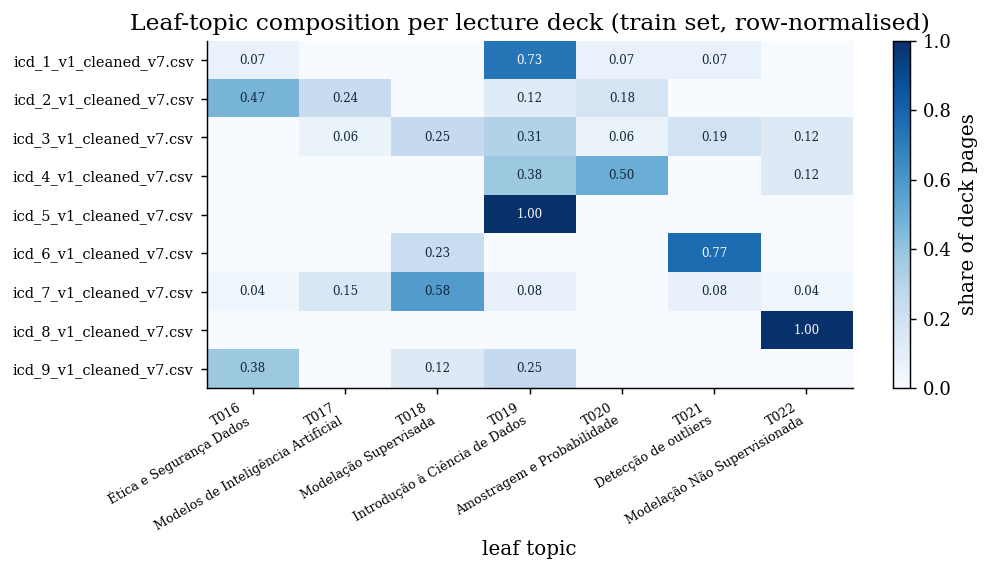

In [23]:
# Topic × deck heatmap — leaf-topic composition of each lecture deck.
from collections import Counter

def page_leaf_topic(doc):
    cnt = Counter(int(t) for t in doc.topics if level_map.get(int(t)) is not None)
    if not cnt:
        return None
    return max(cnt, key=lambda t: (level_map.get(t, -1), cnt[t]))

page_topic = [page_leaf_topic(d) for d in hlda.docs]
assign_df = train_df[['source_file']].copy()
assign_df['leaf'] = page_topic

leaf_ids = sorted(by_level.get(DEPTH - 1, []))
decks    = sorted(assign_df['source_file'].unique())

mat = np.zeros((len(decks), len(leaf_ids)))
for r, deck in enumerate(decks):
    sub = assign_df[assign_df['source_file'] == deck]
    total = len(sub)
    for c, tid in enumerate(leaf_ids):
        mat[r, c] = (sub['leaf'] == tid).sum() / total if total else 0.0

fig, ax = plt.subplots(figsize=(max(8, len(leaf_ids) * 1.1), max(4, len(decks) * 0.5)))
im = ax.imshow(mat, cmap='Blues', aspect='auto', vmin=0, vmax=mat.max() or 1)

ax.set_xticks(range(len(leaf_ids)))
ax.set_xticklabels([f'T{t:03d}\n{ALL_LABELS.get(t, "")}' for t in leaf_ids],
                   fontsize=7, rotation=30, ha='right')
ax.set_yticks(range(len(decks)))
ax.set_yticklabels([d[:28] for d in decks], fontsize=8)
ax.set_xlabel('leaf topic')
ax.set_title('Leaf-topic composition per lecture deck (train set, row-normalised)')

for r in range(len(decks)):
    for c in range(len(leaf_ids)):
        if mat[r, c] > 0.01:
            ax.text(c, r, f'{mat[r, c]:.2f}', ha='center', va='center',
                    fontsize=6.5, color='white' if mat[r, c] > mat.max() * 0.6 else '#12263A')

fig.colorbar(im, ax=ax, label='share of deck pages')
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_ROOT, 'hlda_topic_deck_heatmap.png'), dpi=200, bbox_inches='tight')
plt.show()

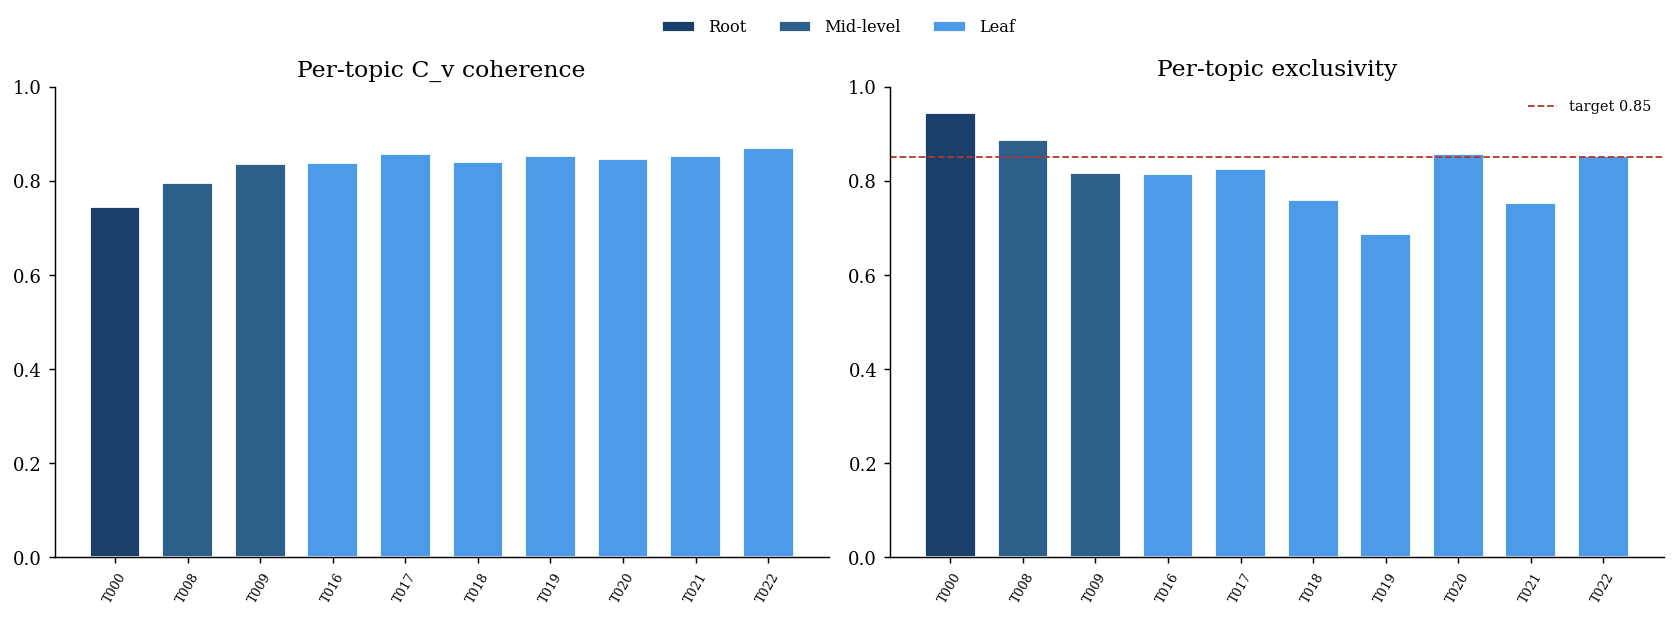

In [24]:
# Per-topic coherence and exclusivity, grouped by level.
coh_by_tid = {}
for lvl, vals in level_coh.items():
    coh_by_tid.update(vals['per_topic'])

ordered = [tid for lvl in sorted(by_level) for tid in by_level[lvl]]
tick_labels = [f'T{t:03d}' for t in ordered]
bar_colours = [LEVEL_COLOURS[level_map[t]] for t in ordered]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, (title, series, ref) in zip(axes, [
    ('Per-topic C_v coherence', [coh_by_tid.get(t, np.nan) for t in ordered], None),
    ('Per-topic exclusivity',   [exclusivity_by_tid.get(t, np.nan) for t in ordered], 0.85),
]):
    x = range(len(ordered))
    ax.bar(x, series, color=bar_colours, edgecolor='white', width=0.7)
    ax.set_xticks(list(x))
    ax.set_xticklabels(tick_labels, rotation=60, fontsize=7)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    if ref is not None:
        ax.axhline(ref, color='#B03A2E', linestyle='--', linewidth=1,
                   label=f'target {ref}')
        ax.legend(frameon=False, fontsize=8)

handles = [mpatches.Patch(facecolor=LEVEL_COLOURS[lvl], edgecolor='white',
                          label=level_names.get(lvl, f'Level {lvl}'))
           for lvl in sorted(by_level)]
fig.legend(handles=handles, loc='upper center', ncol=len(handles),
           frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_ROOT, 'hlda_per_topic_metrics.png'), dpi=200, bbox_inches='tight')
plt.show()